# Lesson 1: Remember the answer
## Staircase and Frog

Run in Jupyter or Google Colab with Python 3. No packages or external input files are required. Shift+Enter runs a cell. Run the setup cell first. Predict each result before running code.

Exercise IDs match the worksheet and slides. Small recursive examples are for learning; use iteration for large inputs. Python stops recursion at about 1,000 nested calls by default, so recursive versions are for small inputs only.

Where a question asks you to write a program, the cell below it is a stub: replace `return None` with your code, then run the check cell. Cells marked **Worked example** explain an idea; read them after you have tried the question.


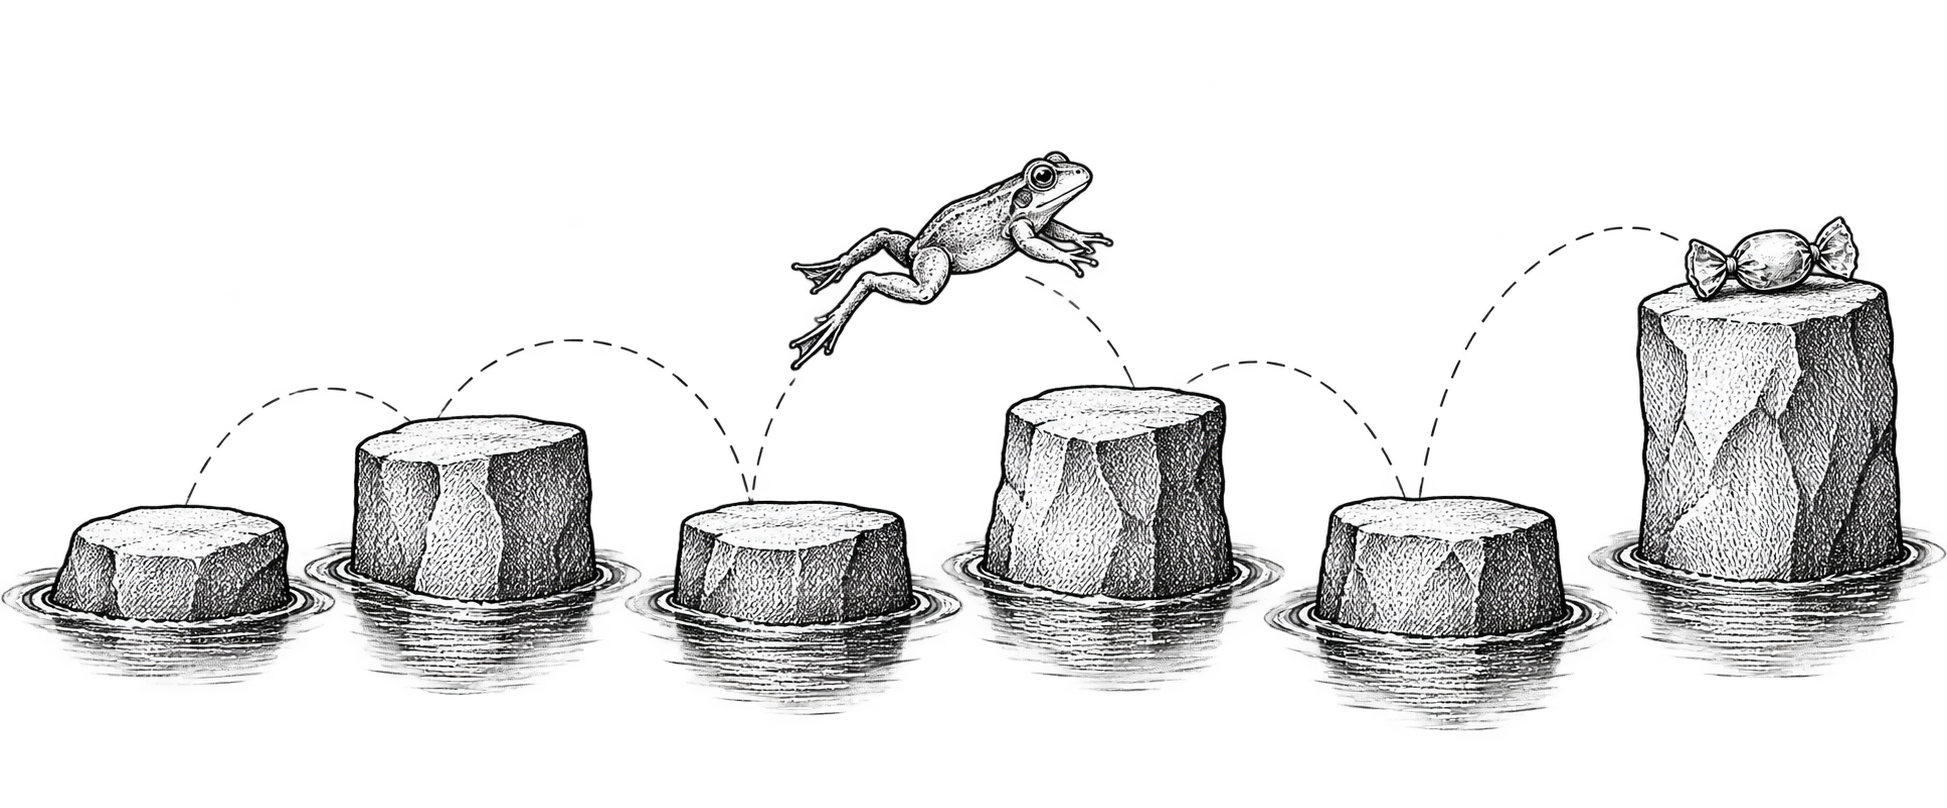

In [ ]:
import sys
print('Ready. Run cells from top to bottom.')


## The route and the rules

### Our route
Start with a brief recursion refresher; choose one warm-up exercise if you already know how calls stop. Then count staircase routes by hand. Write a recursive function, see which questions repeat, and save their answers. Then fill the same answers with a loop. Change the allowed jumps before trying Frog, where the answer is a minimum cost instead of a count.

### Recursion warm-up · L1-01 to L1-04
A function may call itself on a smaller input. The base case answers directly, without another call; every other call must move closer to the base case. A call that is waiting for a smaller call stays unfinished until that call returns its value.

### Staircase rules · L1-05 to L1-13
Start at ground level, called step 0. A move climbs exactly 1 or 2 steps. Count ordered lists of moves that land exactly on the target. For example, [1, 2] and [2, 1] are different routes. In L1-13 only, the permitted moves change to 1 or 3.

### Frog rules · L1-14 to L1-20
Number the stones 0, 1, 2 and so on. Start on stone 0 and finish on the last stone. A jump moves forward by one or two stone positions. Its cost is the absolute height difference: a jump from height 50 to height 30 costs 20. Add every jump cost in a route; find the smallest total.

### Names used in the questions
`ways(n)` is a function returning the number of staircase routes to target step n. `ways[n]` is a list entry storing that count. Parentheses call a function; square brackets read a stored entry. In Frog, `heights[i]` is the height at stone position i, while `best[i]` is the cheapest total cost to reach it.

### What to complete in class
Complete both staircase and Frog: for each, follow the slow recursive solution, save repeated answers, then fill a table with a loop. The recursion warm-up is a short refresher; the remaining warm-up exercises can be used for extra practice. Explain each small example before running a large input.

## Recursion refresher (before L1-01)

**Objective:** follow a function that calls itself and explain why it stops.

A function calling itself is **recursion**. It needs two parts:

- a **base case**: an input answered directly, with no further call;
- a **smaller case**: a call on a smaller input that leads to the base case.

**Code to trace.** The function below returns the sum of the integers from 1 to n. The base case sum_to(0) returns 0. Run the definition cell to make the function available; this does not call it or show the answer.


In [ ]:
def sum_to(n):
    if n == 0:
        return 0
    return n + sum_to(n - 1)


`return` hands a value to the calling function. Python keeps unfinished calls on the **call stack**. Data: `n = 3`. Just before the base case returns, the stack looks like this:

```text
Top       sum_to(0)  can return 0 now
          sum_to(1)  waits for sum_to(0)
          sum_to(2)  waits for sum_to(1)
Bottom    sum_to(3)  waits for sum_to(2)
```

**Your turn.** Fill the missing Returns entries in the table, including each addition. Work from the bottom up. Then predict the value returned by `sum_to(3)`.

Call | Waits for | Returns
--- | --- | ---
sum_to(3) | sum_to(2) | ?
sum_to(2) | sum_to(1) | ?
sum_to(1) | sum_to(0) | ?
sum_to(0) | nothing (base case) | 0


**Your prediction and additions:**

Write your working here before checking.

In [ ]:
# Replace None with your predicted result, then run this cell.
prediction = None
if prediction is None:
    print('Fill the trace and enter your prediction first.')
else:
    actual = sum_to(3)
    print('Your prediction:', prediction)
    print('Returned value:', actual)
    print('Compare each row of your trace with the worked answer below.')


<details><summary>Show the completed trace after your attempt</summary>
<table><tr><th>Call</th><th>Waits for</th><th>Returns</th></tr><tr><td>sum_to(3)</td><td>sum_to(2)</td><td>3 + 3 = 6</td></tr><tr><td>sum_to(2)</td><td>sum_to(1)</td><td>2 + 1 = 3</td></tr><tr><td>sum_to(1)</td><td>sum_to(0)</td><td>1 + 0 = 1</td></tr><tr><td>sum_to(0)</td><td>nothing (base case)</td><td>0</td></tr></table>
</details>


## L1-01: A function that calls itself

A function may call itself on a smaller input. countdown(n) below prints n and then calls countdown(n - 1); when n is 0 it prints Go! and makes no further call. In the table, write every call that countdown(3) makes, in order, what that call prints and which call it makes next.

**Code to trace:** run this definition cell first; it does not print the answer.

In [ ]:
def countdown(n):
    if n == 0:
        print('Go!')
        return
    print(n)
    countdown(n - 1)


Call | Prints | Calls next
--- | --- | ---
countdown(3) | &nbsp; | &nbsp;
&nbsp; | &nbsp; | &nbsp;
&nbsp; | &nbsp; | &nbsp;
&nbsp; | &nbsp; | &nbsp;

**Your prediction / reasoning:**

Write your explanation here.

In [ ]:
# Fill the table above before running this example.
# Change False to True when you are ready to check.
run_example = False
if run_example:
    countdown(3)
else:
    print('Predict first. Set run_example to True to check your answer.')


<details><summary>Show the completed trace after your attempt</summary>
<table><tr><th>Call</th><th>Prints</th><th>Calls next</th></tr><tr><td>countdown(3)</td><td>3</td><td>countdown(2)</td></tr><tr><td>countdown(2)</td><td>2</td><td>countdown(1)</td></tr><tr><td>countdown(1)</td><td>1</td><td>countdown(0)</td></tr><tr><td>countdown(0)</td><td>Go!</td><td>nothing</td></tr></table>
</details>


## L1-02: Wait for the smaller answer

sum_squares(n) returns 0 when n is 0; otherwise it returns n * n + sum_squares(n - 1). A call cannot finish until the call it waits for has returned. Fill the table for sum_squares(4), starting from the bottom row and working up. Write the addition for each returned value.

**Code to trace:** run this definition cell first; it does not print the answer.

In [ ]:
def sum_squares(n):
    if n == 0:
        return 0
    return n * n + sum_squares(n - 1)


Call | Waits for | Returns
--- | --- | ---
sum_squares(4) | &nbsp; | &nbsp;
sum_squares(3) | &nbsp; | &nbsp;
sum_squares(2) | &nbsp; | &nbsp;
sum_squares(1) | &nbsp; | &nbsp;
sum_squares(0) | nothing | 0

**Your prediction / reasoning:**

Write your explanation here.

In [ ]:
# Fill the table above before running this example.
# Change False to True when you are ready to check.
run_example = False
if run_example:
    print(sum_squares(4))
else:
    print('Predict first. Set run_example to True to check your answer.')


<details><summary>Show the completed trace after your attempt</summary>
<table><tr><th>Call</th><th>Waits for</th><th>Returns</th></tr><tr><td>sum_squares(4)</td><td>sum_squares(3)</td><td>16 + 14 = 30</td></tr><tr><td>sum_squares(3)</td><td>sum_squares(2)</td><td>9 + 5 = 14</td></tr><tr><td>sum_squares(2)</td><td>sum_squares(1)</td><td>4 + 1 = 5</td></tr><tr><td>sum_squares(1)</td><td>sum_squares(0)</td><td>1 + 0 = 1</td></tr><tr><td>sum_squares(0)</td><td>nothing</td><td>0</td></tr></table>
</details>


## L1-03: Find the missing base case

power2(n) below should return 2 to the power n: 2 multiplied by itself n times, so power2(3) should be 8. What happens when you call power2(3)? Which value of n can you answer directly, without a smaller call? Add that base case and check that power2(3) now returns 8.

```python
def power2(n):
    return 2 * power2(n - 1)
```

**Start with:**

```python
def power2(n):
    return None  # Replace with your answer.
```

**What each function returns:**
- `power2(n)`: the integer 2 raised to the power n.

**Hints:**
- Trace the inputs until they pass 0. Where should the chain stop?
- Check your repaired function on the stopping input before trying 3.


**Your prediction / reasoning:**

Write your explanation here.

In [ ]:
def power2(n):
    """
    For a nonnegative integer n, return 2 to the power n. Repair the
    missing stopping case before testing.
    """
    # Replace this return with your solution.
    return None


In [ ]:
checks = [
    (power2(0), 1),
    (power2(1), 2),
    (power2(3), 8),
    (power2(6), 64),
]
if any(actual is None for actual, expected in checks):
    print('Not implemented yet. Complete the function above.')
else:
    for number, (actual, expected) in enumerate(checks, 1):
        assert actual == expected, ('check', number, 'expected', expected, 'got', actual)
    print('All checks passed.')


**After completing the function:** Explain why each checked answer follows from the state and its earlier answers.

Follow the arguments 3, 2, 1, 0, -1. Where should the calls stop, and what is 2 to the power 0?

## L1-04: Write a recursive function

factorial(n) is the product 1 × 2 × ... × n, and factorial(0) is 1. Write factorial(n) recursively: first the base case, then one smaller call. Predict factorial(4) before running it. The staircase that follows uses the same pattern, with two smaller calls instead of one.

**Start with:**

```python
def factorial(n):
    return None  # Replace with your answer.
```

**What each function returns:**
- `factorial(n)`: the product of integers 1 through n; for n = 0, return 1.

**Hints:**
- What is the smallest n you can answer directly?
- If you already knew factorial(n - 1), what single step would give factorial(n)?


**Your prediction / reasoning:**

Write your explanation here.

In [ ]:
def factorial(n):
    """
    Return n! = 1 x 2 x ... x n, with factorial(0) = 1. Use recursion:
    the base case first, then one smaller call.
    """
    # Replace this return with your solution.
    return None


In [ ]:
checks = [
    (factorial(0), 1),
    (factorial(1), 1),
    (factorial(4), 24),
    (factorial(6), 720),
]
if any(actual is None for actual, expected in checks):
    print('Not implemented yet. Complete the function above.')
else:
    for number, (actual, expected) in enumerate(checks, 1):
        assert actual == expected, ('check', number, 'expected', expected, 'got', actual)
    print('All checks passed.')


**After completing the function:** Explain why each checked answer follows from the state and its earlier answers.

What is factorial(0)? How is factorial(4) related to factorial(3)?

## L1-05: Five steps, many routes

Start on the ground, called step 0. Each move climbs exactly 1 or 2 steps. Count routes that land exactly on each target from step 1 to step 5. List the routes to step 5 as move lists, such as [1, 2, 2]. Does changing the order make a different route?

Step | 1 | 2 | 3 | 4 | 5
--- | --- | --- | --- | --- | ---
Routes | &nbsp; | &nbsp; | &nbsp; | &nbsp; | &nbsp;

**Your prediction / reasoning:**

Write your explanation here.

## L1-06: The last move explains the sum

The next move must land on step 5. Where can that move start? Use your L1-05 counts for step 4 and step 3. How can these two counts give the answer for step 5?

**Your prediction / reasoning:**

Write your explanation here.

## L1-07: Where recursion stops

Let ways(n) return the number of routes from the ground to target step n, using jumps of 1 or 2. What should ways(0) and ways(-1) return? Use these answers to work out ways(1).

**Your prediction / reasoning:**

Write your explanation here.

## L1-08: The slow recursive program

Write stairs_slow(n), the number of staircase routes to step n with jumps of 1 or 2. Start with the stopping cases, then ask about the two possible starting steps of the final jump. Draw every call made for stairs_slow(3) and write the returned count beside it.

**Start with:**

```python
def stairs_slow(n):
    return None  # Replace with your answer.
```

**What each function returns:**
- `stairs_slow(n)`: the number of ordered routes to step n using jumps of 1 or 2.

**Hints:**
- Which targets can you answer without a smaller call? Think about 0 and about negative targets.
- The last move is 1 or 2 steps. Which smaller targets do those leave?


**Your prediction / reasoning:**

Write your explanation here.

**Recursion depth:** Python stops recursion at about 1,000 nested calls by default, so this recursive version is for small inputs and the small and edge test files only. Use the iterative version for the medium and large files.

In [ ]:
def stairs_slow(n):
    """
    Return the number of routes to step n with jumps of 1 or 2. Use
    plain recursion: stopping cases first, then the two possible last
    jumps.
    """
    # Replace this return with your solution.
    return None


In [ ]:
checks = [
    (stairs_slow(1), 1),
    (stairs_slow(3), 3),
    (stairs_slow(5), 8),
]
if any(actual is None for actual, expected in checks):
    print('Not implemented yet. Complete the function above.')
else:
    for number, (actual, expected) in enumerate(checks, 1):
        assert actual == expected, ('check', number, 'expected', expected, 'got', actual)
    print('All checks passed.')


**After completing the function:** Explain why each checked answer follows from the state and its earlier answers.

Put the base cases before the recursive return.

## L1-09: Repeated questions in the call tree

The diagram shows the first three levels of calls made while counting routes to step 5. Circle calls with the same input. What work does the second call to ways(3) repeat?

The first three call levels (positive targets continue below this drawing):

```text
ways(5)
|-- ways(4)
|   |-- ways(3)
|   `-- ways(2)
`-- ways(3)
    |-- ways(2)
    `-- ways(1)
```

**Your prediction / reasoning:**

Write your explanation here.

## L1-10: A cache keeps an answer

A cache is a dictionary that saves an answer under the input that produced it. We have found 5 routes to step 4. Complete cache[?] = ?. What should a later call to ways(4) return, and which work can it skip?

**Your prediction / reasoning:**

Write your explanation here.

**Recursion depth:** Python stops recursion at about 1,000 nested calls by default, so this recursive version is for small inputs and the small and edge test files only. Use the iterative version for the medium and large files.

**Worked example: read it after you have answered the question above.** It explains the idea and is not one of your exercises.

In [ ]:
def stairs_cached(n):
    cache = {0: 1}
    def ways(step):
        if step < 0:
            return 0
        if step not in cache:
            cache[step] = ways(step - 1) + ways(step - 2)
        return cache[step]
    return ways(n)


In [ ]:
print(stairs_cached(20))

**After running:** Explain why the output follows from the state and its earlier answers.

The key describes the question; the stored value answers it.

## L1-11: Fast work can still mean deep recursion

Caching removes repeated work. Why can a large staircase input still cause RecursionError in Python? What does iteration change?

**Your prediction / reasoning:**

Write your explanation here.

**Worked example: read it after you have answered the question above.** It explains the idea and is not one of your exercises.

In [ ]:
def recursion_demo():
    def descend(n):
        if n == 0:
            return 0
        return 1 + descend(n - 1)
    try:
        descend(sys.getrecursionlimit() + 10)
    except RecursionError:
        return 'Caught RecursionError: too many nested calls.'
    return 'No RecursionError: the limit was not reached.'


In [ ]:
print(recursion_demo())

**After running:** Explain why the output follows from the state and its earlier answers.

Imagine all the calls waiting for the smallest question to return.

## L1-12: Build the table in order

Write stairs_table(n) using a loop. First fill ways[step], the route count, for steps 0 through 5. Which earlier count is available at step 1? Which two are needed from step 2 onwards? Use that order in your code.

**Start with:**

```python
def stairs_table(n):
    return None  # Replace with your answer.
```

**What each function returns:**
- `stairs_table(n)`: the number of ordered routes to step n using jumps of 1 or 2.

**Hints:**
- How long must the list be so that ways[n] exists?
- Which entry do you know before the loop starts?
- When you fill ways[step], which entries must already be filled?


Step | 0 | 1 | 2 | 3 | 4 | 5
--- | --- | --- | --- | --- | --- | ---
ways[step] | 1 | ? | ? | ? | ? | ?

**Your prediction / reasoning:**

Write your explanation here.

In [ ]:
def stairs_table(n):
    """
    Return the number of routes to step n with jumps of 1 or 2. Fill a
    list ways[0..n] with a loop, in increasing order.
    """
    # Replace this return with your solution.
    return None


In [ ]:
checks = [
    (stairs_table(0), 1),
    (stairs_table(1), 1),
    (stairs_table(5), 8),
    (stairs_table(40), 165580141),
]
if any(actual is None for actual, expected in checks):
    print('Not implemented yet. Complete the function above.')
else:
    for number, (actual, expected) in enumerate(checks, 1):
        assert actual == expected, ('check', number, 'expected', expected, 'got', actual)
    print('All checks passed.')


**After completing the function:** Explain why each checked answer follows from the state and its earlier answers.

Write the positions above the counts, not in the same row.

## L1-13: Your turn: jumps of 1 or 3

Write stairs_13(n) by adapting stairs_table from L1-12. Allow only jumps of 1 or 3, never 2. First fill the counts for steps 0 through 7, then write and test your code.

**Start with:**

```python
def stairs_13(n):
    return None  # Replace with your answer.
```

**What each function returns:**
- `stairs_13(n)`: the number of ordered routes to step n using jumps of 1 or 3.

**Hints:**
- Which line of stairs_table depends on the allowed jumps?
- A jump can only start from a step that exists. What must be true before you read an earlier entry?


Step | 0 | 1 | 2 | 3 | 4 | 5 | 6 | 7
--- | --- | --- | --- | --- | --- | --- | --- | ---
ways[step] | 1 | &nbsp; | &nbsp; | &nbsp; | &nbsp; | &nbsp; | &nbsp; | &nbsp;

**Your prediction / reasoning:**

Write your explanation here.

In [ ]:
def stairs_13(n):
    """
    Return the number of routes to step n when each move climbs exactly
    1 or 3 steps. Fill a list in increasing order.
    """
    # Replace this return with your solution.
    return None


In [ ]:
checks = [
    (stairs_13(0), 1),
    (stairs_13(2), 1),
    (stairs_13(7), 9),
]
if any(actual is None for actual, expected in checks):
    print('Not implemented yet. Complete the function above.')
else:
    for number, (actual, expected) in enumerate(checks, 1):
        assert actual == expected, ('check', number, 'expected', expected, 'got', actual)
    print('All exercise checks passed.')


## L1-14: Frog: cost belongs to a whole route

Number the stones 0, 1 and 2; their heights are [10, 20, 30]. A frog starts at stone 0 and may jump forward one or two positions. A jump costs the absolute height difference, so a drop of 10 also costs 10. List all routes to stone 2 and add the jump costs for each.

**Your prediction / reasoning:**

Write your explanation here.

## L1-15: A greedy choice can fail

Use heights [20, 50, 30, 40, 10, 10], at stones 0 through 5. At each stone, choose the cheaper of the next two legal jumps; if costs tie, choose the farther stone. Trace this greedy route and its total cost. Can another complete route cost less?

Stone i | 0 | 1 | 2 | 3 | 4 | 5
--- | --- | --- | --- | --- | --- | ---
heights[i] | 20 | 50 | 30 | 40 | 10 | 10

**Your prediction / reasoning:**

Write your explanation here.

## L1-16: Frog: ask about the last jump

Write frog_slow(heights) with recursive helper cost(i): the cheapest total cost from stone 0 to stone i. Which earlier stones can supply the last jump? Explore both possibilities.

**Start with:**

```python
def frog_slow(heights):
    def cost(i):
        return None  # Your helper goes here.
    return cost(len(heights) - 1)
```

**What each function returns:**
- `frog_slow(heights)`: the cheapest total cost from stone 0 to the last stone.
- `cost(i)`: the cheapest total cost from stone 0 to stone i, including all jumps along the route.

**Hints:**
- What is the smallest i you can answer directly?
- Which earlier stones can the last jump into stone i start from?
- What does cost(i) need to know about each of those stones?


**Your prediction / reasoning:**

Write your explanation here.

**Recursion depth:** Python stops recursion at about 1,000 nested calls by default, so this recursive version is for small inputs and the small and edge test files only. Use the iterative version for the medium and large files.

In [ ]:
def frog_slow(heights):
    """
    Return the cheapest total cost from stone 0 to the last stone.
    cost(i) tries both possible last jumps recursively.
    """
    def cost(i):
        # Returns the cheapest total cost from stone 0 to stone i, including all jumps along the route.
        # Write this helper here.
        return None
    return cost(len(heights) - 1)


In [ ]:
checks = [
    (frog_slow([10, 30, 20, 40]), 30),
    (frog_slow([20, 50, 30, 40, 10, 10]), 30),
]
if any(actual is None for actual, expected in checks):
    print('Not implemented yet. Complete the function above.')
else:
    for number, (actual, expected) in enumerate(checks, 1):
        assert actual == expected, ('check', number, 'expected', expected, 'got', actual)
    print('All checks passed.')


**After completing the function:** Explain why each checked answer follows from the state and its earlier answers.

Each candidate is earlier total cost plus the cost of one final jump.

## L1-17: Frog: cache the stone number

In the recursive Frog solution, what is the cache key? Why can different routes that reach the same stone share an answer?

**Your prediction / reasoning:**

Write your explanation here.

**Recursion depth:** Python stops recursion at about 1,000 nested calls by default, so this recursive version is for small inputs and the small and edge test files only. Use the iterative version for the medium and large files.

**Worked example: read it after you have answered the question above.** It explains the idea and is not one of your exercises.

In [ ]:
def frog_cached(heights):
    cache = {0: 0}
    def cost(i):
        if i not in cache:
            one = cost(i - 1) + abs(heights[i] - heights[i - 1])
            answer = one
            if i >= 2:
                two = cost(i - 2) + abs(heights[i] - heights[i - 2])
                answer = min(one, two)
            cache[i] = answer
        return cache[i]
    return cost(len(heights) - 1)


In [ ]:
print(frog_cached([20, 50, 30, 40, 10, 10]))

**After running:** Explain why the output follows from the state and its earlier answers.

Every call sees the same heights. Only the target stone changes.

## L1-18: Frog: write the iterative solution

Write frog_table(heights) using a loop. Return the cheapest total cost from stone 0 to the last stone. First fill best[i] for heights [20, 50, 30, 40, 10, 10], then turn those steps into Python code. Explain why the loop runs from left to right. Test your function on these heights.

**Start with:**

```python
def frog_table(heights):
    return None  # Replace with your answer.
```

**What each function returns:**
- `frog_table(heights)`: the cheapest total cost from stone 0 to the last stone.

**Hints:**
- What is best[0], before any jump?
- Which earlier entries does best[i] need, and are they filled when the loop reaches i?


Stone i | 0 | 1 | 2 | 3 | 4 | 5
--- | --- | --- | --- | --- | --- | ---
heights[i] | 20 | 50 | 30 | 40 | 10 | 10
best[i] | 0 | ? | ? | ? | ? | ?

**Your prediction / reasoning:**

Write your explanation here.

In [ ]:
def frog_table(heights):
    """
    Return the cheapest total cost from stone 0 to the last stone,
    filling best[i] from left to right.
    """
    # Replace this return with your solution.
    return None


In [ ]:
checks = [
    (frog_table([20, 50, 30, 40, 10, 10]), 30),
    (frog_table([10, 30]), 20),
]
if any(actual is None for actual, expected in checks):
    print('Not implemented yet. Complete the function above.')
else:
    for number, (actual, expected) in enumerate(checks, 1):
        assert actual == expected, ('check', number, 'expected', expected, 'got', actual)
    print('All exercise checks passed.')


## L1-19: Your turn: a new Frog instance

Test your frog_table(heights) from L1-18. For heights [10, 30, 20, 40], first predict best[i] and give one cheapest route, then run your function. Next predict and test the answer for 100,000 equal-height stones. Explain why uncached recursion is unsuitable for that large test.

Stone i | 0 | 1 | 2 | 3
--- | --- | --- | --- | ---
heights[i] | 10 | 30 | 20 | 40
best[i] | 0 | &nbsp; | &nbsp; | &nbsp;

**Your prediction / reasoning:**

Write your explanation here.

**Use your `frog_table` from L1-18.** If you change it, run its cell again before the checks below.

In [ ]:
checks = [
    (frog_table([10, 30, 20, 40]), 30),
    (frog_table([20, 50, 30, 40, 10, 10]), 30),
    (frog_table([7] * 100000), 0),
]
if any(actual is None for actual, expected in checks):
    print('Not implemented yet. Complete the function above.')
else:
    for number, (actual, expected) in enumerate(checks, 1):
        assert actual == expected, ('check', number, 'expected', expected, 'got', actual)
    print('All exercise checks passed.')


## L1-20: Counting and minimising

Both staircase and Frog inspect earlier states. Why does staircase add their answers, while Frog takes a minimum? What does each table entry mean?

**Your prediction / reasoning:**

Write your explanation here.

## Original problem sources
- [Frog 1 - AtCoder Educational DP Contest A](https://atcoder.jp/contests/dp/tasks/dp_a)
- Staircase: Original teaching exercise: moves of 1 or 2, then 1 or 3.